# Calculator and plots of option strategies

This notebook calculates and plots the profit and loss at expiry of option structures:
Bull Call Spread, Bear Call Spread, Bull Put Spread, Bear Put Spread, Long Straddle, Short Straddle, Collar and Iron Butterfly.

Derivatives course, Universidad EIA. This is the second version of my calculator:
- each strategy is a list of legs (type, quantity, strike), so we do not need a different block of code for each one and it is easy to add new ones
- the premiums come from Black-Scholes, so all the examples are consistent
- **correction:** in the first version the Bear Put Spread had the legs inverted (buying the low strike and selling the high one is a bull spread). Now we buy the high strike and sell the low one
- the Collar now includes the stock (a long put plus a short call without the stock is a risk reversal, not a collar)
- the break-evens are found where the P&L changes sign, and not with `np.isclose(payoff, 0, atol=0.1)`, which only found them if they were exactly in the price grid

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

sns.set_theme(style="whitegrid")

## Part 1. Base functions

In [2]:
def bs_price(S, K, T, r, sigma, tipo):
    d1 = (np.log(S / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if tipo == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

def leg_pnl(precio_final, tipo, cantidad, strike, prima):
    # cantidad = +1 if we buy, -1 if we sell. prima = premium paid per unit (for the stock, the purchase price)
    if tipo == "call":
        valor = np.maximum(precio_final - strike, 0)
    elif tipo == "put":
        valor = np.maximum(strike - precio_final, 0)
    else:
        valor = precio_final        # the stock
    return cantidad * (valor - prima)

## Part 2. Definition of the strategies

Spot 100, 3 months, r = 5%, sigma = 25%, strikes 90 / 100 / 110.

In [3]:
S, T, r, sigma = 100, 0.25, 0.05, 0.25
bajo, alto = 90, 110
prima = lambda tipo, K: bs_price(S, K, T, r, sigma, tipo)

estrategias = {
    "Bull Call Spread": [("call", 1, bajo), ("call", -1, alto)],
    "Bear Call Spread": [("call", -1, bajo), ("call", 1, alto)],
    "Bull Put Spread":  [("put", 1, bajo), ("put", -1, alto)],
    "Bear Put Spread":  [("put", 1, alto), ("put", -1, bajo)],
    "Long Straddle":    [("call", 1, S), ("put", 1, S)],
    "Short Straddle":   [("call", -1, S), ("put", -1, S)],
    "Collar":           [("stock", 1, 0), ("put", 1, bajo), ("call", -1, alto)],
    "Iron Butterfly":   [("put", 1, bajo), ("put", -1, S), ("call", -1, S), ("call", 1, alto)],
}

def pnl(patas, precios):
    total = 0
    for tipo, cantidad, K in patas:
        p = S if tipo == "stock" else prima(tipo, K)
        total = total + leg_pnl(precios, tipo, cantidad, K, p)
    return total

## Part 3. Results: maximum profit, maximum loss, net premium and break-evens

In [4]:
precios = np.linspace(0, 300, 30001)
filas = []
for nombre, patas in estrategias.items():
    y = pnl(patas, precios)
    # break-evens: where the P&L changes sign (linear interpolation between two points)
    i = np.where(np.sign(y[:-1]) * np.sign(y[1:]) < 0)[0]
    be = precios[i] - y[i] * (precios[i + 1] - precios[i]) / (y[i + 1] - y[i])
    # if the P&L keeps growing (or falling) at very high prices, it is unlimited
    lejos = pnl(patas, np.array([3000.0]))[0]
    maximo = "unlimited" if lejos > y.max() + 1e-6 else round(y.max(), 2)
    minimo = "unlimited" if lejos < y.min() - 1e-6 else round(y.min(), 2)
    neta = -sum(c * prima(t, K) for t, c, K in patas if t != "stock")
    filas.append([nombre, maximo, minimo, round(neta, 2), ", ".join(str(round(b, 2)) for b in be)])
resumen = pd.DataFrame(filas, columns=["Strategy", "Max profit", "Max loss", "Net premium (+ received)", "Break-even(s)"])
resumen

,Strategy,Max profit,Max loss,Net premium (+ received),Break-even(s)
0,Bull Call Spread,9.77,-10.23,-10.23,100.23
1,Bear Call Spread,10.23,-9.77,10.23,100.23
2,Bull Put Spread,9.52,-10.48,9.52,100.48
3,Bear Put Spread,10.48,-9.52,-9.52,100.48
4,Long Straddle,unlimited,-9.95,-9.95,"90.05, 109.95"
5,Short Straddle,9.95,unlimited,9.95,"90.05, 109.95"
6,Collar,10.89,-9.11,0.89,99.11
7,Iron Butterfly,6.88,-3.12,6.88,"93.12, 106.88"


## Part 4. Plots

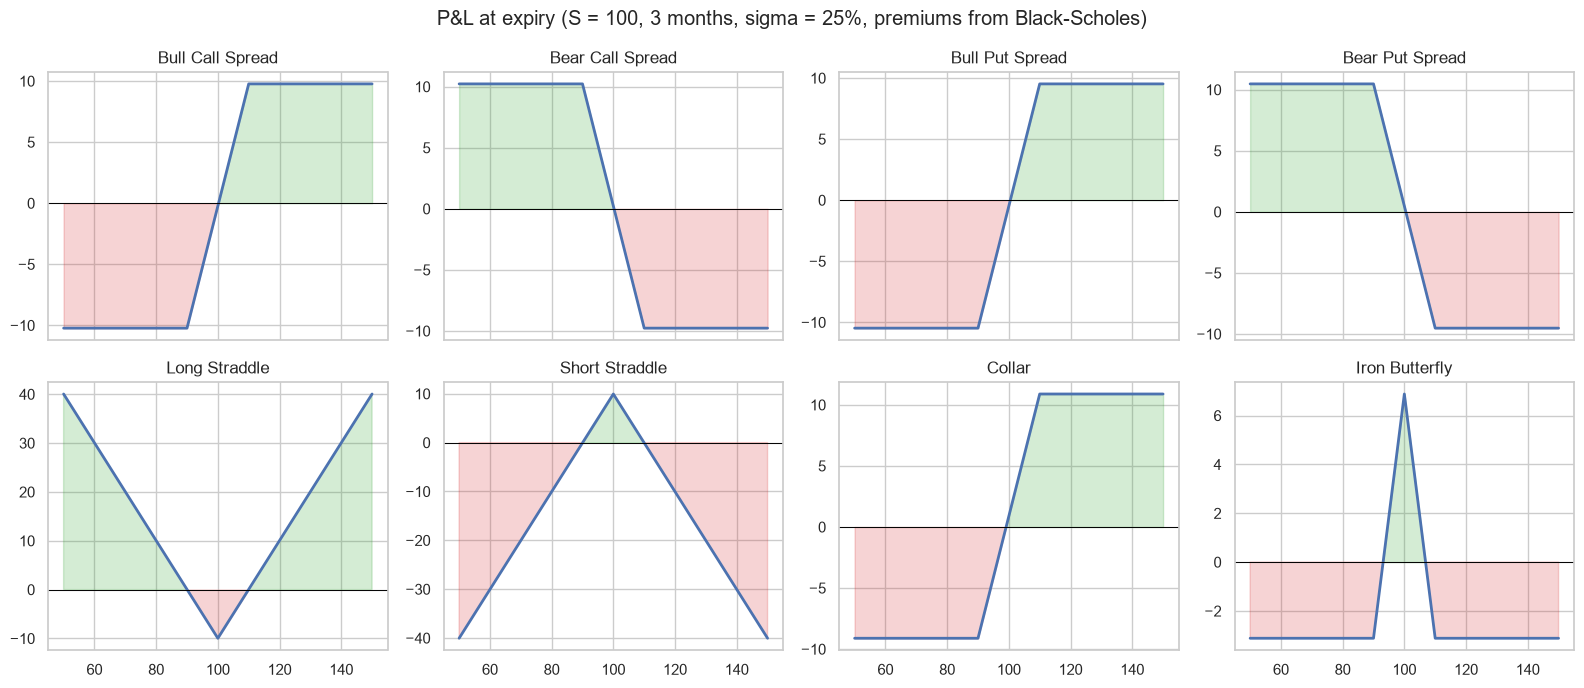

In [5]:
x = np.linspace(50, 150, 1001)
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
for ax, (nombre, patas) in zip(axes.ravel(), estrategias.items()):
    y = pnl(patas, x)
    ax.plot(x, y, lw=2)
    ax.fill_between(x, y, 0, where=y > 0, color="tab:green", alpha=0.2)
    ax.fill_between(x, y, 0, where=y < 0, color="tab:red", alpha=0.2)
    ax.axhline(0, color="black", lw=0.7)
    ax.set_title(nombre)
plt.suptitle("P&L at expiry (S = 100, 3 months, sigma = 25%, premiums from Black-Scholes)")
plt.tight_layout()
plt.savefig("figures/strategies.png", bbox_inches="tight")
plt.show()

## Part 5. Check of the correction

A bear spread must win when the price falls and lose when it goes up:

In [6]:
patas = estrategias["Bear Put Spread"]
print("Bear Put Spread, P&L if the price goes to 50:", round(pnl(patas, np.array([50.0]))[0], 2))
print("Bear Put Spread, P&L if the price goes to 150:", round(pnl(patas, np.array([150.0]))[0], 2))

Bear Put Spread, P&L if the price goes to 50: 10.48
Bear Put Spread, P&L if the price goes to 150: -9.52
